# ASCEND AI — End-to-End AI Career Assistant
## Final CE-2 Machine Learning Notebook

**Purpose:** demonstrate the dataset preparation, NLP, resume-category classification, resume–job similarity, skill extraction, skill-gap analysis, evaluation and model export that support Ascend AI.

**Datasets used:** `resumes(2).csv`, `jobs(2).csv`, `skills(3).csv`, and the engineered `Ascend(2).csv`. Upload all four when prompted. The notebook also accepts the simpler filenames `resumes.csv`, `jobs.csv`, `skills.csv`, and `Ascend.csv`.

> Run cells from top to bottom. All metrics and charts are calculated from the uploaded data at runtime; no scores are hard-coded. Similarity is a text relevance score, not a probability of getting hired.

## 1. Libraries and reproducibility

In [1]:
import os, re, json, warnings, joblib, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from sklearn.metrics.pairwise import cosine_similarity

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries loaded. Random state:", RANDOM_STATE)

Libraries loaded. Random state: 42


## 2. Upload and load the four project datasets
In Google Colab, upload the four CSV files together when the file picker appears.

In [2]:
# Colab upload. If running locally, place the CSVs in the current working directory.
try:
    from google.colab import files
    uploaded = files.upload()
    print("Uploaded:", list(uploaded.keys()))
except ImportError:
    print("Not running in Colab; reading CSVs from the working directory.")

def find_csv(candidates, required=True):
    for name in candidates:
        if os.path.exists(name): return name
    # case-insensitive fallback
    available = {f.lower(): f for f in os.listdir('.') if f.lower().endswith('.csv')}
    for name in candidates:
        if name.lower() in available: return available[name.lower()]
    if required: raise FileNotFoundError(f"Missing one of: {candidates}. Upload the project CSV files.")
    return None

resume_file = find_csv(["resumes(2).csv", "resumes.csv"])
jobs_file = find_csv(["jobs(2).csv", "jobs.csv"])
skills_file = find_csv(["skills(3).csv", "skills.csv"])
engineered_file = find_csv(["Ascend(2).csv", "Ascend.csv"], required=False)

resumes_raw = pd.read_csv(resume_file, encoding="utf-8", encoding_errors="replace")
jobs_raw = pd.read_csv(jobs_file, encoding="utf-8", encoding_errors="replace")
skills_raw = pd.read_csv(skills_file, encoding="utf-8", encoding_errors="replace")
engineered_raw = pd.read_csv(engineered_file, encoding="utf-8", encoding_errors="replace") if engineered_file else None
print("Loaded files:", resume_file, jobs_file, skills_file, engineered_file)

Not running in Colab; reading CSVs from the working directory.
Loaded files: resumes.csv jobs.csv skills.csv Ascend.csv


## 3. Dataset overview and schema validation

In [3]:
print("RESUMES:", resumes_raw.shape, list(resumes_raw.columns))
print("JOBS:", jobs_raw.shape, list(jobs_raw.columns))
print("SKILLS:", skills_raw.shape, list(skills_raw.columns))
if engineered_raw is not None: print("ENGINEERED RESUMES:", engineered_raw.shape, list(engineered_raw.columns))

# Validate expected columns and fail with a useful message rather than silently guessing.
for col in ["Category", "Resume"]:
    if col not in resumes_raw.columns: raise ValueError(f"Resume dataset must contain '{col}'. Found {list(resumes_raw.columns)}")
for col in ["Job Title", "Job Description"]:
    if col not in jobs_raw.columns: raise ValueError(f"Jobs dataset must contain '{col}'. Found {list(jobs_raw.columns)}")
for col in ["label_cleaned", "altLabels"]:
    if col not in skills_raw.columns: raise ValueError(f"Skills dataset must contain '{col}'. Found {list(skills_raw.columns)}")

dataset_summary = pd.DataFrame({
    "Dataset": ["Resumes", "Jobs", "Skills"] + (["Engineered resumes"] if engineered_raw is not None else []),
    "Rows": [len(resumes_raw), len(jobs_raw), len(skills_raw)] + ([len(engineered_raw)] if engineered_raw is not None else []),
    "Columns": [len(resumes_raw.columns), len(jobs_raw.columns), len(skills_raw.columns)] + ([len(engineered_raw.columns)] if engineered_raw is not None else [])
})
display(dataset_summary)
display(resumes_raw.head(3)); display(jobs_raw.head(3)); display(skills_raw.head(3))

RESUMES: (962, 2) ['Category', 'Resume']
JOBS: (2277, 3) ['Unnamed: 0', 'Job Title', 'Job Description']
SKILLS: (13893, 2) ['label_cleaned', 'altLabels']
ENGINEERED RESUMES: (166, 6) ['Category', 'Category_encoded', 'resume_length', 'word_count', 'skill_count', 'Resume']


,Dataset,Rows,Columns
0,Resumes,962,2
1,Jobs,2277,3
2,Skills,13893,2
3,Engineered resumes,166,6


Category                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

,Unnamed: 0,Job Title,Job Description
0,0,Flutter Developer,"We are looking for hire experts flutter developer. So you are eligible this post then apply your resume.\nJob Types: Full-time, Part-time\nSalary: ₹20,000.00 - ₹40,000.00 per month\nBenefits:\nFlexible schedule\nFood allowance\nSchedule:\nDay shift\nSupplemental Pay:\nJoining bonus\nOvertime pay\nExperience:\ntotal work: 1 year (Preferred)\nHousing rent subsidy:\nYes\nIndustry:\nSoftware Development\nWork Remotely:\nTemporarily due to COVID-19"
1,1,Django Developer,PYTHON/DJANGO (Developer/Lead) - Job Code(PDJ - 04)\nStrong Python experience in API development (REST/RPC).\nExperience working with API Frameworks (Django/flask).\nExperience evaluating and improving the efficiency of programs in a Linux environment.\nAbility to effectively handle multiple tasks with a high level of accuracy and attention to detail.\nGood verbal and written communication skills.\nWorking knowledge of SQL.\nJSON experience preferred.\nGood knowledge in automated unit testing using PyUnit.
2,2,Machine Learning,"Data Scientist (Contractor)\n\nBangalore, IN\n\nResponsibilities\n\nWe are looking for a capable data scientist to join the Analytics team, reporting locally in India Bangalore. This person’s responsibilities include research, design and development of Machine Learning and Deep Learning algorithms to tackle a variety of Fraud oriented challenges. The data scientist will work closely with software engineers and program managers to deliver end-to-end products, including: data collection in big scale and analysis, exploring different algorithmic approaches, model development, assessment and validation – all the way through production.\n\nQualifications\n\nAt least 3 years of hands-on development of complex Machine Learning models using modern frameworks and tools, ideally Python based.\nSolid understanding of statistics and applied mathematics\nCreative thinker with a proven ability to tackle open problems and apply non-trivial solutions.\nExperience in software development using Python, Java or a similar language.\nAny Graduate or M.Sc. in Computer Science, Mathematics or equivalent, preferably in Machine Learning\nAbility to write clean and concise code\nQuick learner, independent, methodical, and detail oriented.\nTeam player, positive attitude, collaborative, good communication skills.\nDedicated, makes things happen.\nFlexible, capable of making decisions in an ambiguous and changing environment.\n\nAdvantages:\n\nPrior experience as a software developer or data engineer – advantage\nExperience with Big data – advantage\nExperience with Spark – big advantage\nExperience with Deep Learning frameworks (PyTorch, TensorFlow, Keras) – advantage.\nExperience in the Telecommunication domain and/or Fraud prevention - advantage"


,label_cleaned,altLabels
0,manage musical staff,manage staff of music coordinate duties of musical staff manage music staff direct musical staff manage musical staff
1,supervise correctional procedures,oversee prison procedures manage correctional procedures monitor correctional procedures manage prison procedures monitor prison procedures supervise correctional procedures oversee correctional procedures
2,apply anti-oppressive practices,apply non-oppressive practices apply an anti-oppressive practice make use of anti-oppressive practices act in a non-oppressive way identify oppression in societies and groups apply anti-oppressive practices apply anti-oppresive practice use anti-oppressive practices


## 4. Data quality checks and preprocessing

In [4]:
resumes = resumes_raw[["Category", "Resume"]].copy()
jobs = jobs_raw[["Job Title", "Job Description"]].copy()
skills = skills_raw[["label_cleaned", "altLabels"]].copy()

# Normalize nulls, whitespace, encoding artefacts and duplicate rows.
def clean_text(value):
    if pd.isna(value): return ""
    text = str(value).replace("\ufeff", " ").replace("\xa0", " ")
    text = text.replace("â€¢", " ").replace("•", " ").replace("–", "-").replace("—", "-")
    text = re.sub(r"\s+", " ", text)
    return text.strip()

for col in ["Category", "Resume"]: resumes[col] = resumes[col].map(clean_text)
for col in ["Job Title", "Job Description"]: jobs[col] = jobs[col].map(clean_text)
for col in ["label_cleaned", "altLabels"]: skills[col] = skills[col].map(clean_text)

quality = pd.DataFrame({
    "Dataset": ["Resumes", "Jobs", "Skills"],
    "Duplicate rows before removal": [resumes.duplicated().sum(), jobs.duplicated().sum(), skills.duplicated().sum()],
    "Missing/blank key values": [((resumes.Category == "") | (resumes.Resume == "")).sum(), ((jobs["Job Title"] == "") | (jobs["Job Description"] == "")).sum(), (skills.label_cleaned == "").sum()]
})
display(quality)
resumes = resumes[(resumes.Category != "") & (resumes.Resume != "")].drop_duplicates().reset_index(drop=True)
jobs = jobs[(jobs["Job Title"] != "") & (jobs["Job Description"] != "")].drop_duplicates().reset_index(drop=True)
skills = skills[skills.label_cleaned != ""].drop_duplicates().reset_index(drop=True)
print("After cleaning:", resumes.shape, jobs.shape, skills.shape)

,Dataset,Duplicate rows before removal,Missing/blank key values
0,Resumes,796,0
1,Jobs,7,0
2,Skills,0,0


After cleaning: (166, 2) (2270, 2) (13893, 2)


## 5. Exploratory Data Analysis (EDA)

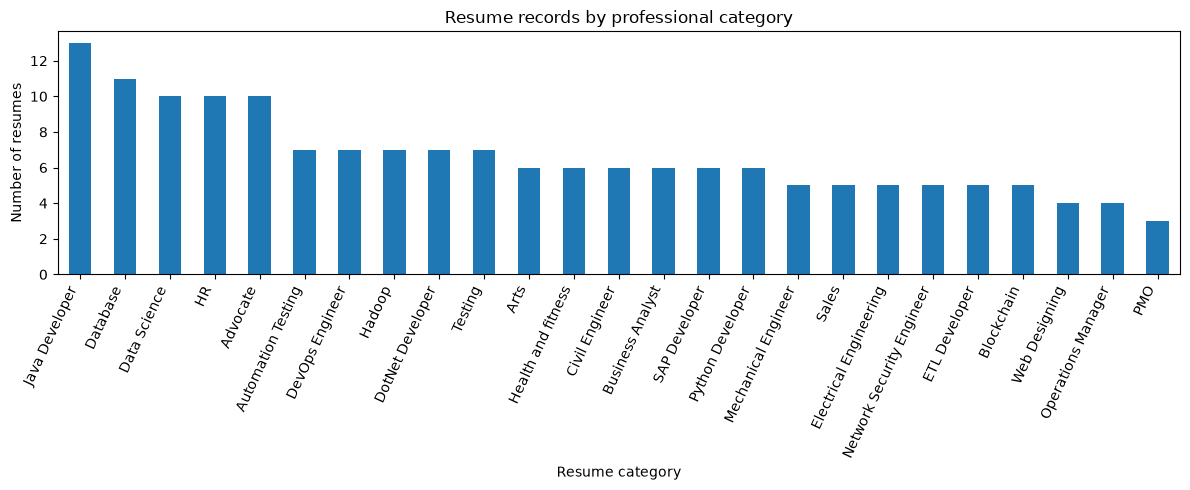

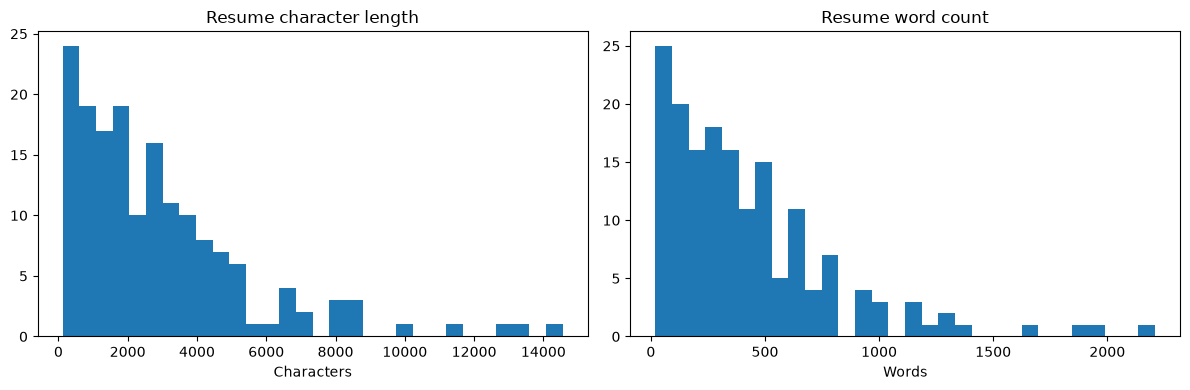

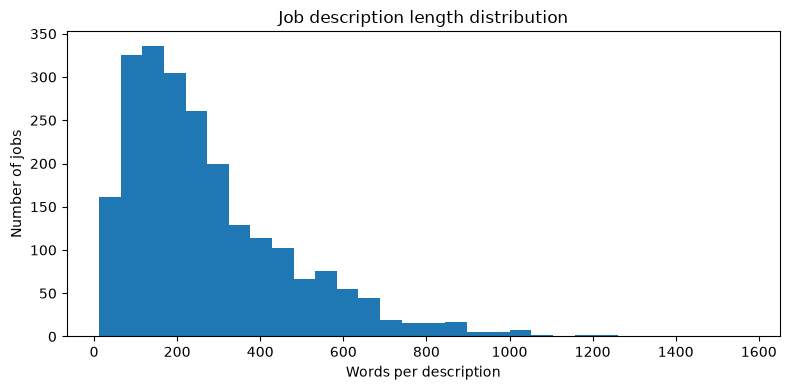

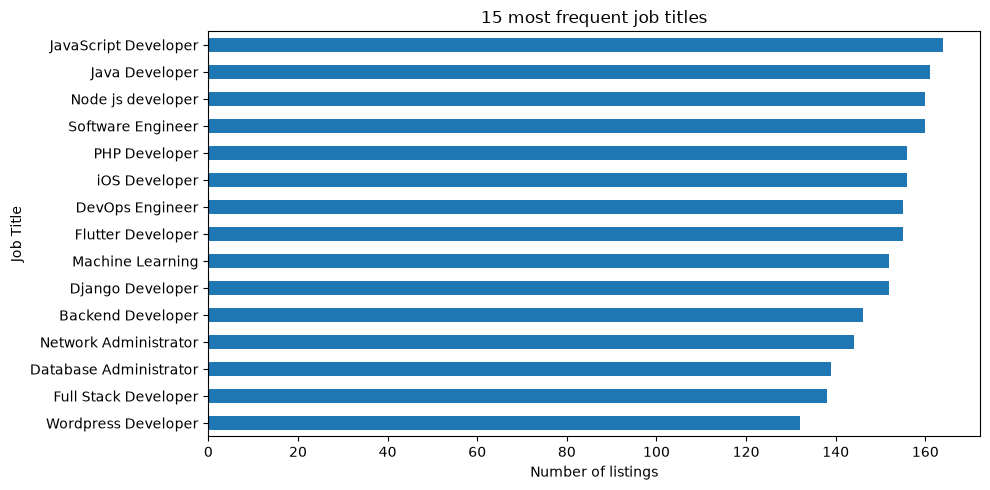

Category count: 25
Resume word-count summary:


,word_count
count,166.000000
mean,424.771084
std,380.604490
min,19.000000
25%,161.250000
50%,330.000000
75%,571.500000
max,2209.000000


Job description word-count summary:


,description_word_count
count,2270.000000
mean,275.480617
std,201.321418
min,12.000000
25%,130.000000
50%,222.000000
75%,370.000000
max,1573.000000


In [5]:
# Category frequency
category_counts = resumes["Category"].value_counts()
plt.figure(figsize=(12, 5)); category_counts.plot(kind="bar")
plt.title("Resume records by professional category"); plt.xlabel("Resume category"); plt.ylabel("Number of resumes")
plt.xticks(rotation=65, ha="right"); plt.tight_layout(); plt.show()

# Resume length and word count are calculated from cleaned text.
resumes["resume_length"] = resumes.Resume.str.len()
resumes["word_count"] = resumes.Resume.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(resumes.resume_length, bins=30); ax[0].set_title("Resume character length"); ax[0].set_xlabel("Characters")
ax[1].hist(resumes.word_count, bins=30); ax[1].set_title("Resume word count"); ax[1].set_xlabel("Words")
plt.tight_layout(); plt.show()

# Job-description length and frequent job titles
jobs["description_word_count"] = jobs["Job Description"].str.split().str.len()
plt.figure(figsize=(8, 4)); plt.hist(jobs.description_word_count, bins=30)
plt.title("Job description length distribution"); plt.xlabel("Words per description"); plt.ylabel("Number of jobs"); plt.tight_layout(); plt.show()
plt.figure(figsize=(10, 5)); jobs["Job Title"].value_counts().head(15).sort_values().plot(kind="barh")
plt.title("15 most frequent job titles"); plt.xlabel("Number of listings"); plt.tight_layout(); plt.show()

print("Category count:", resumes.Category.nunique())
print("Resume word-count summary:"); display(resumes.word_count.describe().to_frame())
print("Job description word-count summary:"); display(jobs.description_word_count.describe().to_frame())

## 6. Feature engineering and skill vocabulary preparation

Canonical labels in skills.csv: 13893
Filtered relevant skill terms: 5250


,Category,resume_length,word_count,skill_count
0,Data Science,4733,670,11
1,Data Science,1177,163,2
2,Data Science,1838,265,13
3,Data Science,6864,993,12
4,Data Science,427,69,3
5,Data Science,685,103,3
6,Data Science,1674,241,6
7,Data Science,8055,1153,10
8,Data Science,1751,249,10
9,Data Science,4317,686,12


Mean detected skills per resume: 4.01


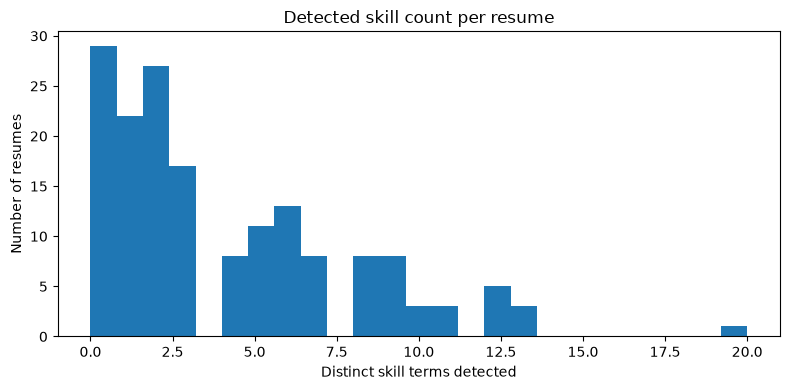

In [6]:
# Build clean skill vocabulary from ESCO canonical labels while filtering generic English stopwords and non-skill phrases.
IRRELEVANT_TERMS = {
    "less", "plan", "source", "service", "create", "check", "health", "equipment", "operation",
    "maintenance", "energy", "history", "logic", "migration", "scratch", "assembly", "logging",
    "ecosystems", "decommissioning", "improvise", "crafting", "troubleshoot", "consultation",
    "ethics", "aesthetics", "chef", "us", "set-up", "governance", "guidance", "mining", "programming",
    "prayer", "pregnancy", "childbirth", "hair", "obesity", "imitation jewellery", "reflexology",
    "medicines", "natural gas", "petroleum", "politics", "philosophy", "literature", "sociology",
    "criminology", "genetics", "nutrition", "dietetics", "exercise physiology", "food science",
    "fine arts", "pneumatics", "crimping", "sensors", "photography", "solar energy",
    "english", "hindi", "marathi", "tamil", "punjabi", "german", "french", "swedish", "latin",
    "gather data", "unstructured data", "work independently", "work efficiently", "solve problems",
    "solve technical problems", "make decisions", "meet deadlines", "lead a team", "manage resources",
    "cope with stress", "personal development", "company policies", "promote company",
    "represent the company", "resolve conflicts", "working condition", "quality standards",
    "business model", "business processes", "sales activities", "manage inventory", "communication"
}
VERB_PREFIXES = (
    "manage ", "supervise ", "apply ", "control ", "identify ", "perform ", "ensure ", "show ",
    "train ", "lead ", "handle ", "develop ", "maintain ", "operate ", "conduct ", "assist ",
    "advise ", "prepare ", "coordinate ", "monitor ", "check ", "provide ", "use ", "create ",
    "carry out ", "organize ", "organise ", "inspect ", "install ", "repair ", "clean ", "assemble ",
    "collect ", "compile ", "promote ", "represent ", "resolve ", "solve ", "make ", "meet ", "work "
)

canonical_skills = {re.sub(r"_[0-9]+$", "", s).strip() for s in skills.label_cleaned.str.lower().str.strip() if s.strip()}
all_skill_terms = sorted(
    s for s in canonical_skills
    if (len(s) >= 3 or s in {"r", "c"})
    and s not in IRRELEVANT_TERMS
    and "," not in s
    and len(s.split()) <= 3
    and not any(s.startswith(vp) for vp in VERB_PREFIXES)
)
skill_set = set(all_skill_terms)
print("Canonical labels in skills.csv:", len(canonical_skills))
print("Filtered relevant skill terms:", len(all_skill_terms))

# Fast O(N) n-gram word-boundary skill extraction (unigrams, bigrams, trigrams)
def extract_skills(text):
    text = clean_text(text).lower()
    tokens = [t.rstrip('.') for t in re.findall(r"\b[a-z0-9_\+#\.\/]+\b", text) if t.rstrip('.')]
    n = len(tokens)
    found = set()
    for k in (1, 2, 3):
        for i in range(n - k + 1):
            phrase = " ".join(tokens[i:i+k])
            if phrase in skill_set:
                found.add(phrase)
    return sorted(found)

resumes["extracted_skills"] = resumes.Resume.apply(extract_skills)
resumes["skill_count"] = resumes.extracted_skills.str.len()
resumes["resume_length"] = resumes.Resume.str.len()
resumes["word_count"] = resumes.Resume.str.split().str.len()
display(resumes[["Category", "resume_length", "word_count", "skill_count"]].head(10))
print("Mean detected skills per resume:", round(resumes.skill_count.mean(), 2))

plt.figure(figsize=(8, 4)); plt.hist(resumes.skill_count, bins=25)
plt.title("Detected skill count per resume"); plt.xlabel("Distinct skill terms detected"); plt.ylabel("Number of resumes"); plt.tight_layout(); plt.show()

## 7. Feature selection and target encoding

In [7]:
# Text is the principal predictive input; category is the supervised target.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(resumes.Category)
X_text = resumes.Resume.astype(str)
print("Target classes:", len(label_encoder.classes_))
print("Class names:", list(label_encoder.classes_))
print("Text samples:", len(X_text))

# Numeric engineered features are retained for analysis and the resume profile,
# while TF-IDF is used for the NLP classification experiment.
engineered_features = resumes[["resume_length", "word_count", "skill_count"]].copy()
print("Selected engineered features:", list(engineered_features.columns))
display(engineered_features.describe())

Target classes: 25
Class names: ['Advocate', 'Arts', 'Automation Testing', 'Blockchain', 'Business Analyst', 'Civil Engineer', 'Data Science', 'Database', 'DevOps Engineer', 'DotNet Developer', 'ETL Developer', 'Electrical Engineering', 'HR', 'Hadoop', 'Health and fitness', 'Java Developer', 'Mechanical Engineer', 'Network Security Engineer', 'Operations Manager', 'PMO', 'Python Developer', 'SAP Developer', 'Sales', 'Testing', 'Web Designing']
Text samples: 166
Selected engineered features: ['resume_length', 'word_count', 'skill_count']


,resume_length,word_count,skill_count
count,166.000000,166.000000,166.000000
mean,2914.024096,424.771084,4.012048
std,2609.664646,380.604490,3.752959
min,124.000000,19.000000,0.000000
25%,1015.750000,161.250000,1.000000
50%,2302.000000,330.000000,3.000000
75%,3825.250000,571.500000,6.000000
max,14552.000000,2209.000000,20.000000


## 8. Train-test split and TF-IDF vectorization

In [8]:
# Stratified split preserves category proportions in train and test sets.
class_counts = pd.Series(y).value_counts()
if class_counts.min() < 2:
    raise ValueError("At least two examples per category are required for a stratified train/test split. Check dataset duplicates/classes.")
X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

# TF-IDF: term frequency × inverse document frequency, using unigrams and bigrams.
# Vectorizer is inside each Pipeline so it is fitted only on training data (prevents leakage).
print("TF-IDF configuration: max_features=5000, ngram_range=(1,2), stop_words='english'")

Training rows: 132 | Test rows: 34
TF-IDF configuration: max_features=5000, ngram_range=(1,2), stop_words='english'


## 9. Model 1 — Logistic Regression

In [9]:
logistic_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, stop_words="english", ngram_range=(1, 2), sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE))
])
logistic_model.fit(X_train, y_train)
pred_lr = logistic_model.predict(X_test)
print("Logistic Regression training complete.")
print("Example predicted category:", label_encoder.inverse_transform(pred_lr[:5]))

Logistic Regression training complete.
Example predicted category: ['Database' 'Operations Manager' 'Blockchain' 'Automation Testing'
 'Civil Engineer']


## 10. Model 2 — Linear Support Vector Machine

In [10]:
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, stop_words="english", ngram_range=(1, 2), sublinear_tf=True)),
    ("classifier", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
])
svm_model.fit(X_train, y_train)
pred_svm = svm_model.predict(X_test)
print("Linear SVM training complete.")
print("Example predicted category:", label_encoder.inverse_transform(pred_svm[:5]))

Linear SVM training complete.
Example predicted category: ['Database' 'Operations Manager' 'Blockchain' 'DevOps Engineer'
 'Civil Engineer']


## 11. Model evaluation — accuracy, precision, recall and F1-score

In [11]:
def metric_row(name, y_true, y_pred):
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Precision (weighted)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
            "Recall (weighted)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
            "F1-score (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0)}

metrics_df = pd.DataFrame([metric_row("Logistic Regression", y_test, pred_lr), metric_row("Linear SVM", y_test, pred_svm)])
display(metrics_df.style.format({c: "{:.4f}" for c in metrics_df.columns if c != "Model"}))
best_name = metrics_df.sort_values("F1-score (weighted)", ascending=False).iloc[0]["Model"]
best_model = logistic_model if best_name == "Logistic Regression" else svm_model
print("Best model by weighted F1-score:", best_name)

                 Model  Accuracy  Precision (weighted)  Recall (weighted)  F1-score (weighted)
0  Logistic Regression  0.882353              0.855392           0.882353             0.855042
1           Linear SVM  0.882353              0.845588           0.882353             0.850140

Best model by weighted F1-score: Logistic Regression


## 12. Classification report and confusion matrices

LOGISTIC REGRESSION — classification report
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         2
                     Arts       1.00      1.00      1.00         1
       Automation Testing       0.33      1.00      0.50         1
               Blockchain       1.00      1.00      1.00         1
         Business Analyst       1.00      1.00      1.00         1
           Civil Engineer       1.00      1.00      1.00         1
             Data Science       1.00      1.00      1.00         2
                 Database       1.00      1.00      1.00         2
          DevOps Engineer       0.00      0.00      0.00         1
         DotNet Developer       1.00      1.00      1.00         2
            ETL Developer       1.00      1.00      1.00         1
   Electrical Engineering       1.00      1.00      1.00         1
                       HR       1.00      1.00      1.00         2
                 

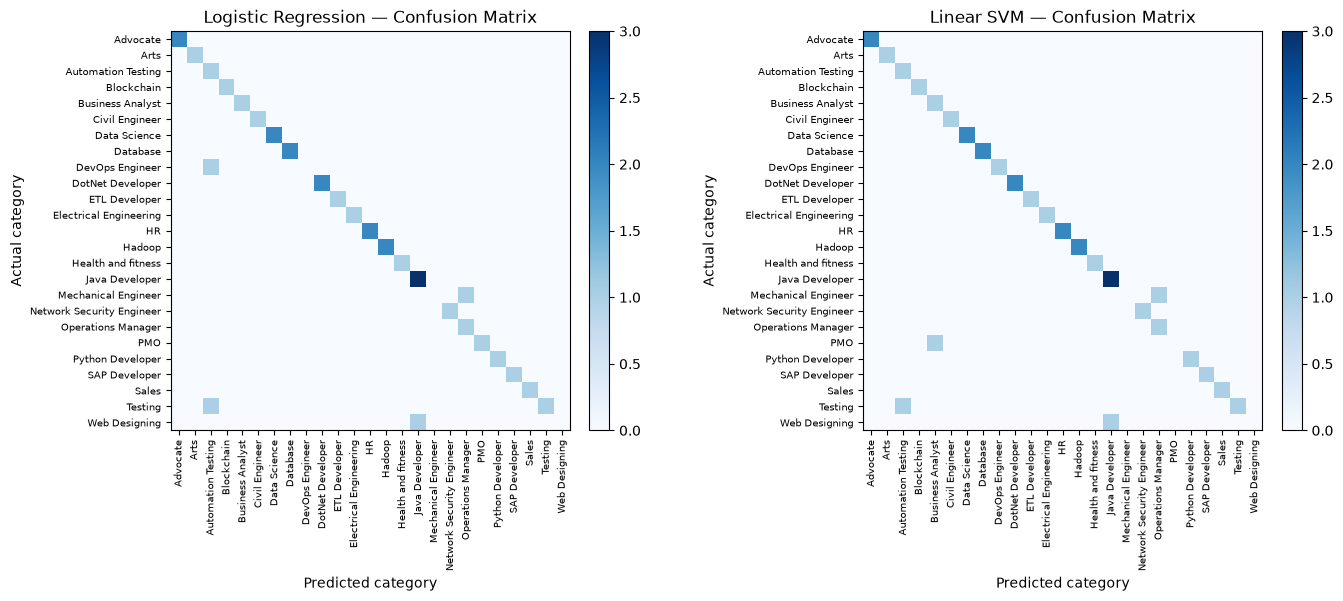

In [12]:
print("LOGISTIC REGRESSION — classification report")
print(classification_report(y_test, pred_lr, labels=np.arange(len(label_encoder.classes_)),
                            target_names=label_encoder.classes_, zero_division=0))
print("LINEAR SVM — classification report")
print(classification_report(y_test, pred_svm, labels=np.arange(len(label_encoder.classes_)),
                            target_names=label_encoder.classes_, zero_division=0))

# Display confusion matrices. For many categories, labels are rotated and figure size scales.
fig, axes = plt.subplots(1, 2, figsize=(max(14, len(label_encoder.classes_)*0.55), 6))
for ax, pred, title in [(axes[0], pred_lr, "Logistic Regression"), (axes[1], pred_svm, "Linear SVM")]:
    cm = confusion_matrix(y_test, pred, labels=np.arange(len(label_encoder.classes_)))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(title + " — Confusion Matrix"); ax.set_xlabel("Predicted category"); ax.set_ylabel("Actual category")
    ax.set_xticks(range(len(label_encoder.classes_))); ax.set_yticks(range(len(label_encoder.classes_)))
    ax.set_xticklabels(label_encoder.classes_, rotation=90, fontsize=7); ax.set_yticklabels(label_encoder.classes_, fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

## 13. Visual comparison of model performance

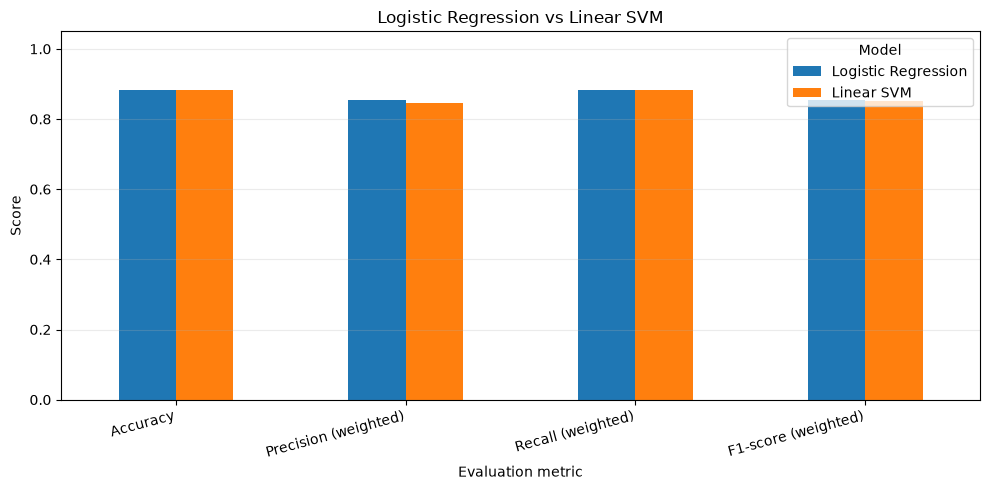

In [13]:
metric_cols = ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)"]
ax = metrics_df.set_index("Model")[metric_cols].T.plot(kind="bar", figsize=(10, 5))
ax.set_title("Logistic Regression vs Linear SVM"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.05); ax.set_xlabel("Evaluation metric")
plt.xticks(rotation=15, ha="right"); plt.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

## 14. Stratified cross-validation

,Fold,Logistic Regression,Linear SVM
0,1,0.807143,0.807143
1,2,0.879192,0.914509
2,3,0.917056,0.893030


LR mean ± std: 0.8678 ± 0.0456
SVM mean ± std: 0.8716 ± 0.0464


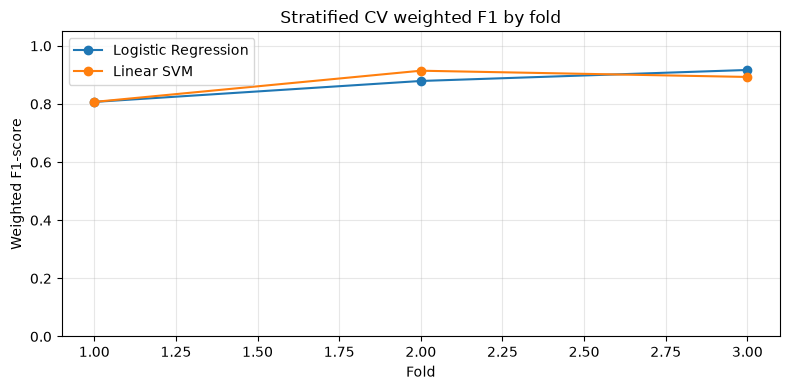

In [14]:
# Cross-validation gives a second estimate of generalization.
# Use up to 5 folds, limited by the smallest class count.
min_class_count = int(pd.Series(y).value_counts().min())
n_splits = min(5, min_class_count)
if n_splits >= 2:
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    cv_lr = cross_val_score(logistic_model, X_text, y, cv=cv, scoring="f1_weighted", n_jobs=-1)
    cv_svm = cross_val_score(svm_model, X_text, y, cv=cv, scoring="f1_weighted", n_jobs=-1)
    cv_df = pd.DataFrame({"Fold": np.arange(1, n_splits+1), "Logistic Regression": cv_lr, "Linear SVM": cv_svm})
    display(cv_df); print("LR mean ± std:", round(cv_lr.mean(),4), "±", round(cv_lr.std(),4))
    print("SVM mean ± std:", round(cv_svm.mean(),4), "±", round(cv_svm.std(),4))
    cv_df.set_index("Fold").plot(marker="o", figsize=(8,4), ylim=(0,1.05), title="Stratified CV weighted F1 by fold")
    plt.ylabel("Weighted F1-score"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else:
    print("Cross-validation skipped: a category has fewer than 2 examples.")

## 15. Resume–job matching using TF-IDF and cosine similarity

,Resume category,Job title,Similarity (%)
0,Data Science,Flutter Developer,0.66
1,Data Science,Django Developer,0.84
2,Data Science,Machine Learning,6.68
3,Data Science,iOS Developer,3.86
4,Data Science,Full Stack Developer,1.66
5,Data Science,Java Developer,1.67
6,Data Science,Full Stack Developer,2.48
7,Data Science,JavaScript Developer,3.64
8,Data Science,DevOps Engineer,4.36
9,Data Science,Software Engineer,6.02


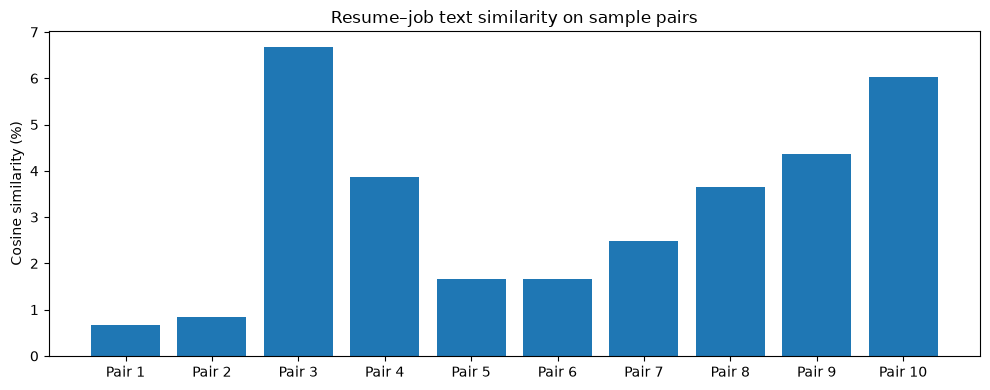

In [15]:
def resume_job_similarity(resume_text, job_description):
    docs = [clean_text(resume_text), clean_text(job_description)]
    if not docs[0] or not docs[1]: return 0.0
    vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1,2))
    matrix = vectorizer.fit_transform(docs)
    return float(cosine_similarity(matrix[0:1], matrix[1:2])[0,0] * 100)

# Demonstrate on a sample of available real records. This is a similarity score, not a hiring probability.
match_rows = []
for i in range(min(10, len(resumes))):
    r = resumes.iloc[i]
    # Compare against a reproducible sample of job descriptions; do not assume category names map to job titles.
    j = jobs.iloc[i % len(jobs)]
    score = resume_job_similarity(r.Resume, j["Job Description"])
    match_rows.append({"Resume category": r.Category, "Job title": j["Job Title"], "Similarity (%)": round(score, 2)})
matching_demo = pd.DataFrame(match_rows)
display(matching_demo)
plt.figure(figsize=(10,4)); plt.bar(range(len(matching_demo)), matching_demo["Similarity (%)"])
plt.xticks(range(len(matching_demo)), [f"Pair {i+1}" for i in range(len(matching_demo))]); plt.ylabel("Cosine similarity (%)")
plt.title("Resume–job text similarity on sample pairs"); plt.tight_layout(); plt.show()

## 16. Skill extraction and skill-gap analysis


PAIR 1: Data Science resume vs Flutter Developer
Matched: []
Missing: []

PAIR 2: Data Science resume vs Django Developer
Matched: ['python']
Missing: ['sql']

PAIR 3: Data Science resume vs Machine Learning
Matched: ['deep learning', 'java', 'machine learning', 'mathematics', 'python']
Missing: ['algorithms', 'computer science', 'spark', 'statistics']

PAIR 4: Data Science resume vs iOS Developer
Matched: []
Missing: ['ios']

PAIR 5: Data Science resume vs Full Stack Developer
Matched: []
Missing: ['angular', 'computer science', 'javascript']

PAIR 6: Data Science resume vs Java Developer
Matched: []
Missing: ['computer science', 'database', 'mysql']

PAIR 7: Data Science resume vs Full Stack Developer
Matched: ['computer science']
Missing: ['java', 'javascript', 'nosql']

PAIR 8: Data Science resume vs JavaScript Developer
Matched: []
Missing: ['javascript']

PAIR 9: Data Science resume vs DevOps Engineer
Matched: ['python']
Missing: ['devops', 'hadoop', 'hardware components', 'java

,Resume category,Job title,Required skills found,Matched skills,Missing skills,Skill coverage (%)
0,Data Science,Flutter Developer,0,0,0,NaN
1,Data Science,Django Developer,2,1,1,50.000000
2,Data Science,Machine Learning,9,5,4,55.555556
3,Data Science,iOS Developer,1,0,1,0.000000
4,Data Science,Full Stack Developer,3,0,3,0.000000
5,Data Science,Java Developer,3,0,3,0.000000
6,Data Science,Full Stack Developer,4,1,3,25.000000
7,Data Science,JavaScript Developer,1,0,1,0.000000
8,Data Science,DevOps Engineer,9,1,8,11.111111
9,Data Science,Software Engineer,4,1,3,25.000000


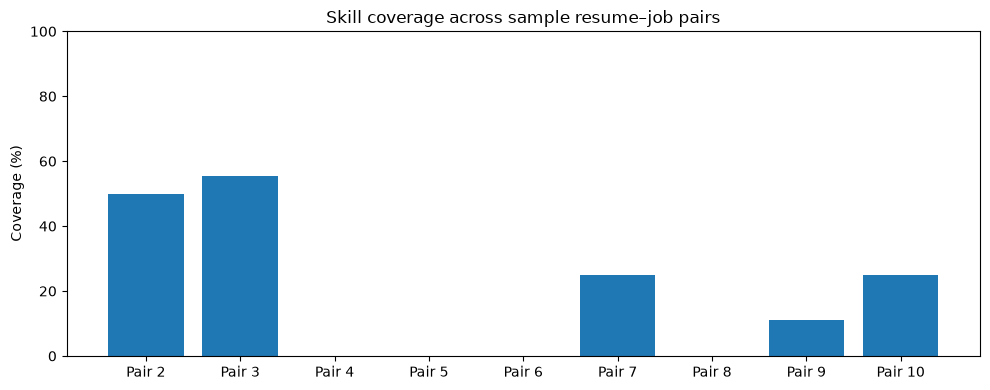

In [16]:
def skill_gap(resume_text, job_description):
    resume_found = set(extract_skills(resume_text))
    job_found = set(extract_skills(job_description))
    matched = sorted(resume_found & job_found)
    missing = sorted(job_found - resume_found)
    coverage = (len(matched) / len(job_found) * 100) if job_found else np.nan
    return matched, missing, coverage, sorted(job_found)

# Analyze first 10 resume/job pairs and show matched and missing terms.
gap_rows = []
for i in range(min(10, len(resumes), len(jobs))):
    r, j = resumes.iloc[i], jobs.iloc[i]
    matched, missing, coverage, required = skill_gap(r.Resume, j["Job Description"])
    gap_rows.append({"Resume category": r.Category, "Job title": j["Job Title"],
                     "Required skills found": len(required), "Matched skills": len(matched),
                     "Missing skills": len(missing), "Skill coverage (%)": coverage})
    print(f"\nPAIR {i+1}: {r.Category} resume vs {j['Job Title']}")
    print("Matched:", matched[:30]); print("Missing:", missing[:30])
gap_df = pd.DataFrame(gap_rows)
display(gap_df)
valid_gap = gap_df.dropna(subset=["Skill coverage (%)"])
if not valid_gap.empty:
    plt.figure(figsize=(10,4)); plt.bar(range(len(valid_gap)), valid_gap["Skill coverage (%)"])
    plt.xticks(range(len(valid_gap)), [f"Pair {i+1}" for i in valid_gap.index], rotation=0)
    plt.ylabel("Coverage (%)"); plt.ylim(0,100); plt.title("Skill coverage across sample resume–job pairs")
    plt.tight_layout(); plt.show()
else:
    print("No identifiable skills were found in the selected job-description samples; no coverage graph can be calculated.")

## 17. Skill vocabulary and dataset visualizations

,Skill,Resume frequency
0,database,57
1,sql,54
2,java,43
3,mysql,30
4,python,29
5,operating systems,26
6,javascript,23
7,sql server,22
8,computer science,21
9,electronics,20


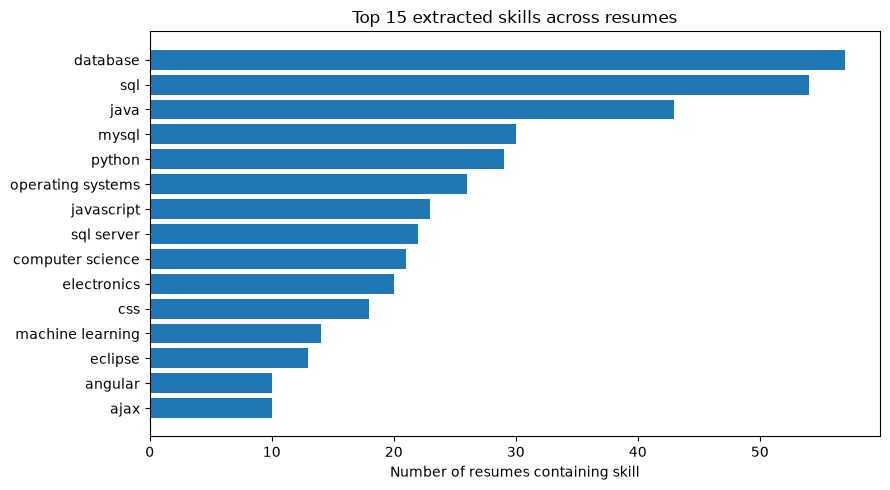

Engineered dataset columns: ['Category', 'Category_encoded', 'resume_length', 'word_count', 'skill_count', 'Resume']


Category  Category_encoded  resume_length  word_count  skill_count                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

,resume_length,word_count,skill_count
count,166.000000,166.000000,166.000000
mean,2848.957831,408.301205,5.421687
std,2548.505807,365.438673,4.212882
min,124.000000,19.000000,0.000000
25%,996.500000,156.000000,2.000000
50%,2238.500000,325.000000,4.000000
75%,3730.250000,550.750000,8.000000
max,14168.000000,2113.000000,24.000000


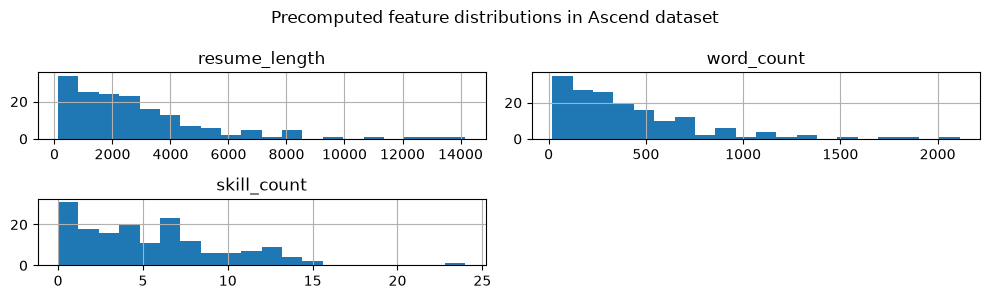

In [17]:
# Most frequent skill terms detected in the resume corpus.
from collections import Counter
skill_counts = Counter(skill for skill_list in resumes.extracted_skills for skill in skill_list)
top_skills = pd.DataFrame(skill_counts.most_common(15), columns=["Skill", "Resume frequency"])
display(top_skills)
if not top_skills.empty:
    plt.figure(figsize=(9,5)); plt.barh(top_skills.Skill[::-1], top_skills["Resume frequency"][::-1])
    plt.title("Top 15 extracted skills across resumes"); plt.xlabel("Number of resumes containing skill"); plt.tight_layout(); plt.show()

# Compare engineered dataset values if available; use it as an independent prepared dataset check.
if engineered_raw is not None:
    print("Engineered dataset columns:", list(engineered_raw.columns))
    display(engineered_raw.head())
    numeric_cols = [c for c in ["resume_length", "word_count", "skill_count"] if c in engineered_raw.columns]
    if numeric_cols:
        display(engineered_raw[numeric_cols].describe())
        engineered_raw[numeric_cols].hist(figsize=(10,3), bins=20); plt.suptitle("Precomputed feature distributions in Ascend dataset"); plt.tight_layout(); plt.show()

## 18. Results and interpretation

In [18]:
print("FINAL EXPERIMENT SUMMARY")
print("------------------------")
print("Resume records used:", len(resumes))
print("Job descriptions used:", len(jobs))
print("Skill vocabulary terms:", len(all_skill_terms))
print("Resume categories:", len(label_encoder.classes_))
print("Selected model by weighted F1:", best_name)
display(metrics_df)

print("Interpretation guide:")
print("- Accuracy: fraction of category predictions that are correct.")
print("- Precision: weighted proportion of predicted category labels that are correct.")
print("- Recall: weighted proportion of actual category records recovered.")
print("- F1: weighted harmonic mean of precision and recall.")
print("- Cosine similarity: overlap in TF-IDF text direction; it is not an ATS standard or hiring probability.")
print("- Skill coverage: matched detected job skills divided by detected job skills; vocabulary coverage is limited by the skill dictionary.")

FINAL EXPERIMENT SUMMARY
------------------------
Resume records used: 166
Job descriptions used: 2270
Skill vocabulary terms: 5250
Resume categories: 25
Selected model by weighted F1: Logistic Regression


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Logistic Regression,0.882353,0.855392,0.882353,0.855042
1,Linear SVM,0.882353,0.845588,0.882353,0.850140


Interpretation guide:
- Accuracy: fraction of category predictions that are correct.
- Precision: weighted proportion of predicted category labels that are correct.
- Recall: weighted proportion of actual category records recovered.
- F1: weighted harmonic mean of precision and recall.
- Cosine similarity: overlap in TF-IDF text direction; it is not an ATS standard or hiring probability.
- Skill coverage: matched detected job skills divided by detected job skills; vocabulary coverage is limited by the skill dictionary.


## 19. Limitations and future scope

### Limitations
- Resume category labels are the dataset targets; the classifier predicts a resume's category, not candidate quality or hiring success.
- The job dataset is not explicitly paired with each resume, so the sample matching demonstration compares reproducible rows and should not be interpreted as ground-truth relevance.
- TF-IDF and cosine similarity are lexical baselines; they may miss semantic equivalence and context.
- Skill extraction depends on the supplied vocabulary and alternative labels; skills absent from the dictionary can be missed.
- A similarity or coverage score should not be presented as an official ATS score.

### Future scope
- Create a manually reviewed resume–job relevance dataset and evaluate ranking with Precision@K, Recall@K and NDCG.
- Add sentence-transformer embeddings for semantic matching and compare against TF-IDF.
- Improve PDF/DOCX parsing, skill normalization and synonym handling.
- Add course recommendation evaluation using verified course metadata and learner feedback.
- Evaluate fairness and category-wise error rates before real recruitment use.

## 20. Export trained models and supporting artifacts

In [19]:
os.makedirs("ascend_ai_artifacts", exist_ok=True)
joblib.dump(logistic_model, "ascend_ai_artifacts/logistic_regression_tfidf.joblib")
joblib.dump(svm_model, "ascend_ai_artifacts/linear_svm_tfidf.joblib")
joblib.dump(label_encoder, "ascend_ai_artifacts/label_encoder.joblib")
joblib.dump(all_skill_terms, "ascend_ai_artifacts/skill_vocabulary.joblib")

artifact_metrics = {
    "selected_model": best_name,
    "records": int(len(resumes)),
    "categories": int(len(label_encoder.classes_)),
    "test_records": int(len(y_test)),
    "metrics": metrics_df.to_dict(orient="records"),
    "cv_n_splits": int(n_splits),
    "cv_lr_f1_mean": round(float(cv_lr.mean()), 4),
    "cv_lr_f1_std": round(float(cv_lr.std()), 4),
    "cv_svm_f1_mean": round(float(cv_svm.mean()), 4),
    "cv_svm_f1_std": round(float(cv_svm.std()), 4),
    "similarity_method": "TF-IDF + cosine similarity",
    "skill_method": "ESCO label and alternative-label dictionary matching"
}
with open("ascend_ai_artifacts/evaluation_metrics.json", "w") as f: json.dump(artifact_metrics, f, indent=2)

# Reload and verify the exported classifier produces identical predictions.
reloaded = joblib.load("ascend_ai_artifacts/linear_svm_tfidf.joblib")
assert np.array_equal(reloaded.predict(X_test), svm_model.predict(X_test))
print("Artifacts exported and reload verification passed.")
print(os.listdir("ascend_ai_artifacts"))

Artifacts exported and reload verification passed.
['skill_vocabulary.joblib', 'logistic_regression_tfidf.joblib', 'evaluation_metrics.json', 'label_encoder.joblib', 'linear_svm_tfidf.joblib']


## 21. Download the artifacts (Google Colab)

In [20]:
# Creates a ZIP containing model files and evaluation metrics.
import shutil
shutil.make_archive("ascend_ai_artifacts", "zip", "ascend_ai_artifacts")
try:
    from google.colab import files
    files.download("ascend_ai_artifacts.zip")
except ImportError:
    print("ZIP saved in the current working directory: ascend_ai_artifacts.zip")

ZIP saved in the current working directory: ascend_ai_artifacts.zip


## Final conclusion
Ascend AI combines resume text classification, TF-IDF representation, cosine-similarity matching and dictionary-based skill-gap analysis. The notebook provides a reproducible academic workflow: inspect and clean the supplied datasets, engineer resume features, train and evaluate two supervised classifiers, demonstrate job-text matching, inspect missing skills, visualize the results and export reusable model artifacts. Use the actual values printed by your run in the CE-2 presentation and report.